# Домашнее задание 1

**Датасет:** [Amazon Reviews 2023, Video Games](https://amazon-reviews-2023.github.io/main.html) от McAuley Lab. Используются [оценки из 5-core выборки](https://amazon-reviews-2023.github.io/data_processing/5core.html) и метаданные товаров. Одна строка оценок — отзыв пользователя о товаре с оценкой от 1 до 5 и временем публикации. Рекомендуем товары, которых нет в обучающей истории пользователя. Релевантным считаем товар с отложенной оценкой 4 или 5.

Исходный файл оценок содержит **814 586 взаимодействий, 94 762 пользователя и 25 612 товаров**.

In [1]:
import gzip
import hashlib
import json
import math
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11
pd.set_option("display.max_colwidth", 65)

## 1. Загрузка исходных данных

Архив оценок содержит `user_id`, `parent_asin`, `rating`, `timestamp`; архив товаров — `parent_asin`, `title`, `categories`, `store`. `timestamp`

In [2]:
raw_dir = Path("data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)
source_files = {
    "Video_Games.csv.gz": (
        "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Video_Games.csv.gz",
        "a2bde5f3b945960d161538c200dd87845e6ee471b46da96410dde61613c6901c",
    ),
    "meta_Video_Games.jsonl.gz": (
        "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Video_Games.jsonl.gz",
        "ced9696b0874121327a438bfe9d3d01aba45da158e58f94f4920352d75fc1fc9",
    ),
}

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for block in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

for name, (url, expected) in source_files.items():
    destination = raw_dir / name
    if not destination.exists():
        temporary = raw_dir / f"{name}.part"
        print(f"Загрузка {name}...")
        with urllib.request.urlopen(url, timeout=60) as source, temporary.open("wb") as target:
            for block in iter(lambda: source.read(1024 * 1024), b""):
                target.write(block)
        temporary.replace(destination)
    if file_sha256(destination) != expected:
        raise ValueError(f"Неверная контрольная сумма: {name}")
    print(f"{name}: {destination.stat().st_size / 1024**2:.1f} МиБ, SHA-256 совпал")

Video_Games.csv.gz: 12.2 МиБ, SHA-256 совпал
meta_Video_Games.jsonl.gz: 98.3 МиБ, SHA-256 совпал


In [3]:
ratings = pd.read_csv(raw_dir / "Video_Games.csv.gz")
print(f"Исходные оценки: {len(ratings):,}; пользователей: {ratings.user_id.nunique():,}; товаров: {ratings.parent_asin.nunique():,}")
print("Пропуски в исходных оценках:", ratings.isna().sum().to_dict())
print("Повторные пары пользователь–товар:", ratings.duplicated(["user_id", "parent_asin"]).sum())
print("Оценки по шкале 1–5:", ratings.rating.value_counts().sort_index().to_dict())

Исходные оценки: 814,586; пользователей: 94,762; товаров: 25,612
Пропуски в исходных оценках: {'user_id': 0, 'parent_asin': 0, 'rating': 0, 'timestamp': 0}
Повторные пары пользователь–товар: 0
Оценки по шкале 1–5: {1.0: 52563, 2.0: 36809, 3.0: 70347, 4.0: 134800, 5.0: 520067}


## 2. Очистка, подвыборка и EDA

Удаляем строки без ID, оценки или времени и оценки вне диапазона 1–5. Для повторной пары пользователь–товар оставляем запись с самым поздним временем. Затем выбираем 2 500 товаров с наибольшим числом оценок; при равенстве сортируем по `parent_asin`. Среди пользователей с минимум пятью оценками этих товаров выбираем 10 000 самых активных. После отбора пользователей товары без оценок исчезают автоматически.

In [4]:
frame = ratings[["user_id", "parent_asin", "rating", "timestamp"]].dropna().copy()
frame["user_id"] = frame.user_id.astype(str)
frame["parent_asin"] = frame.parent_asin.astype(str)
frame["rating"] = pd.to_numeric(frame.rating, errors="coerce")
frame["timestamp"] = pd.to_numeric(frame.timestamp, errors="coerce")
frame = frame.dropna(subset=["rating", "timestamp"])
frame = frame.loc[frame.rating.between(1, 5)].copy()
clean_count = len(frame)
frame = frame.sort_values(["timestamp", "parent_asin", "user_id"], kind="stable")
frame = frame.drop_duplicates(["user_id", "parent_asin"], keep="last")
deduplicated_count = len(frame)

item_counts = frame.groupby("parent_asin").size().rename("n").reset_index()
selected_items = set(item_counts.sort_values(["n", "parent_asin"], ascending=[False, True], kind="stable").head(2500).parent_asin)
frame = frame.loc[frame.parent_asin.isin(selected_items)].copy()
item_sample_count = len(frame)
user_counts = frame.groupby("user_id").size()
frame = frame.loc[frame.user_id.map(user_counts).ge(5)].copy()
active_user_count = len(frame)
user_ranks = frame.groupby("user_id").size().rename("n").reset_index()
selected_users = set(user_ranks.sort_values(["n", "user_id"], ascending=[False, True], kind="stable").head(10000).user_id)
frame = frame.loc[frame.user_id.isin(selected_users)].copy()

print(f"После очистки: {clean_count:,}; после удаления дублей: {deduplicated_count:,}")
print(f"После отбора товаров: {item_sample_count:,}; после порога активности: {active_user_count:,}")
print(f"Итог: {len(frame):,} оценок, {frame.user_id.nunique():,} пользователей, {frame.parent_asin.nunique():,} товаров")

После очистки: 814,586; после удаления дублей: 814,586
После отбора товаров: 452,825; после порога активности: 308,359
Итог: 141,683 оценок, 10,000 пользователей, 2,498 товаров


In [5]:
wanted = set(frame.parent_asin)
metadata = {}
metadata_rows = 0
with gzip.open(raw_dir / "meta_Video_Games.jsonl.gz", "rt", encoding="utf-8") as source:
    for line in source:
        metadata_rows += 1
        record = json.loads(line)
        item = record.get("parent_asin")
        if item in wanted and item not in metadata:
            metadata[item] = record

def item_features(source):
    source = source or {}
    categories = source.get("categories") or ["__missing__"]
    if isinstance(categories, str):
        categories = [categories]
    return {
        "title": str(source.get("title") or "__missing__"),
        "categories": [str(value) for value in categories[:3]],
        "store": str(source.get("store") or "__missing__"),
    }

user_ids = sorted(frame.user_id.unique().tolist())
item_ids = sorted(frame.parent_asin.unique().tolist())
user_map = {value: index for index, value in enumerate(user_ids)}
item_map = {value: index for index, value in enumerate(item_ids)}
item_metadata = [item_features(metadata.get(item)) for item in item_ids]
frame["u"] = frame.user_id.map(user_map).astype(int)
frame["i"] = frame.parent_asin.map(item_map).astype(int)
events = frame.rename(columns={"parent_asin": "item_id"}).sort_values(["u", "timestamp", "item_id"], kind="stable").reset_index(drop=True)
rank = events.groupby("u").cumcount()
sizes = events.groupby("u").u.transform("size")
events["split"] = "train"
events.loc[rank == sizes - 2, "split"] = "validation"
events.loc[rank == sizes - 1, "split"] = "test"

class Dataset:
    def __init__(self, events, train, validation, test, user_ids, item_ids, item_metadata):
        self.events = events
        self.train = train
        self.validation = validation
        self.test = test
        self.user_ids = user_ids
        self.item_ids = item_ids
        self.item_metadata = item_metadata
        self.n_users = len(user_ids)
        self.n_items = len(item_ids)

    def train_items(self, user):
        return set(self.train.loc[self.train.u == user, "i"])

data = Dataset(
    events,
    events.loc[events.split == "train"].copy(),
    events.loc[events.split == "validation"].copy(),
    events.loc[events.split == "test"].copy(),
    user_ids, item_ids, item_metadata,
)
print(f"Строк в исходных метаданных: {metadata_rows:,}; найдены метаданные для {len(metadata):,} из {data.n_items:,} товаров")
print(f"train={len(data.train):,}, validation={len(data.validation):,}, test={len(data.test):,}")

Строк в исходных метаданных: 137,269; найдены метаданные для 2,498 из 2,498 товаров
train=121,683, validation=10,000, test=10,000


In [6]:
user_activity = events.groupby("u").size()
item_popularity = events.groupby("i").size()
category_counts = Counter(category for meta in item_metadata for category in meta["categories"])
missing_categories = sum("__missing__" in meta["categories"] for meta in item_metadata)
missing_stores = sum(meta["store"] == "__missing__" for meta in item_metadata)
print("Пропуски в итоговых оценках:", events[["user_id", "item_id", "rating", "timestamp"]].isna().sum().to_dict())
print("Повторные пары пользователь–товар:", events.duplicated(["user_id", "item_id"]).sum())
print("Оценок на пользователя, медиана / 90-й процентиль / максимум:", *user_activity.quantile([.5, .9, 1]).round().astype(int))
print("Оценок на товар, медиана / 90-й процентиль / максимум:", *item_popularity.quantile([.5, .9, 1]).round().astype(int))
print(f"Разреженность матрицы пользователь–товар: {1 - len(events) / (data.n_users * data.n_items):.2%}")
print(f"Товаров без категорий: {missing_categories}; без магазина: {missing_stores}")
print("Уникальных категорий:", len(category_counts), "; уникальных магазинов:", len({meta["store"] for meta in item_metadata}))

Пропуски в итоговых оценках: {'user_id': 0, 'item_id': 0, 'rating': 0, 'timestamp': 0}
Повторные пары пользователь–товар: 0
Оценок на пользователя, медиана / 90-й процентиль / максимум: 11 22 191
Оценок на товар, медиана / 90-й процентиль / максимум: 36 119 773
Разреженность матрицы пользователь–товар: 99.43%
Товаров без категорий: 40; без магазина: 4
Уникальных категорий: 58 ; уникальных магазинов: 314


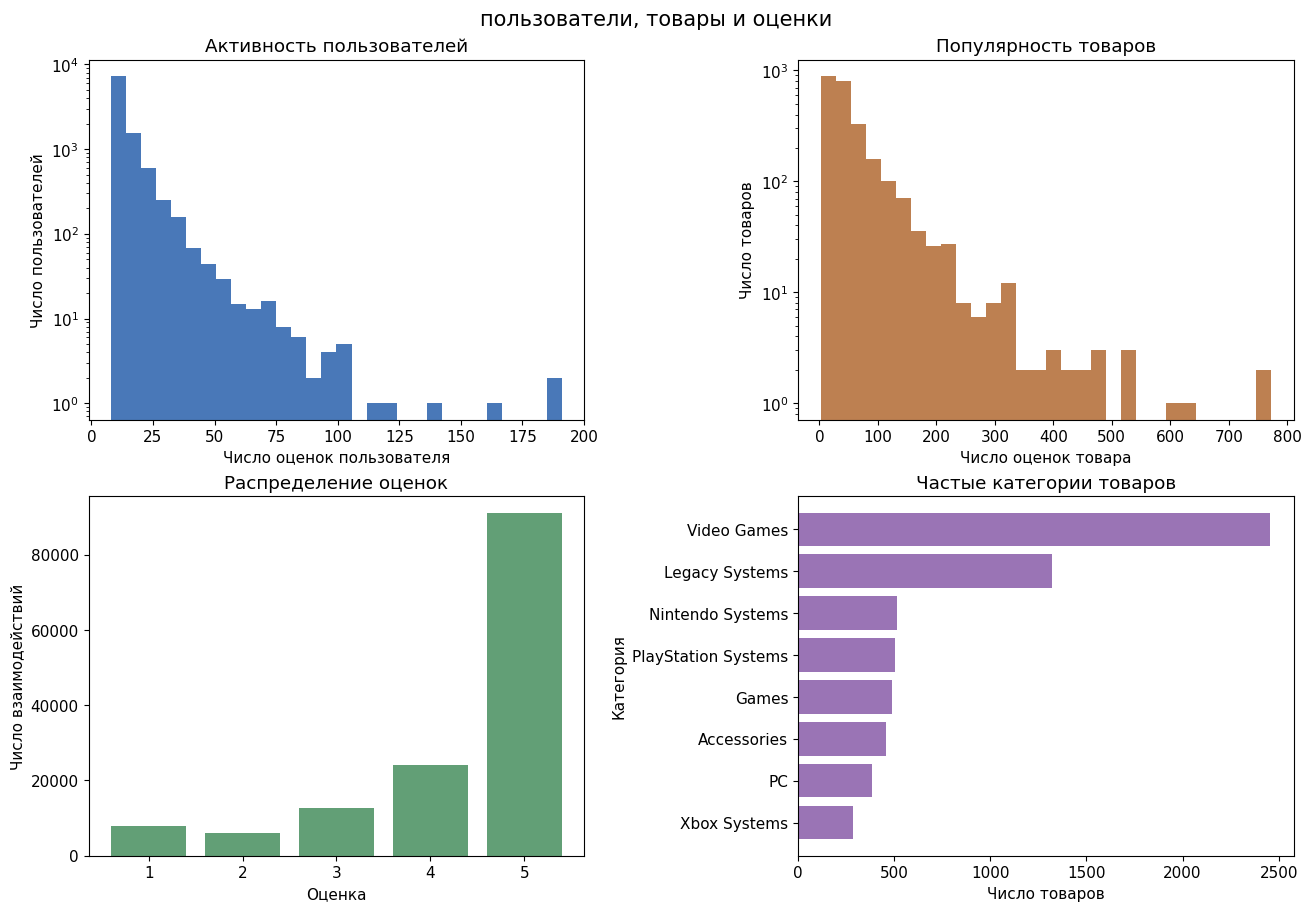

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
axes[0, 0].hist(user_activity, bins=30, color="#4978b8")
axes[0, 0].set(title="Активность пользователей", xlabel="Число оценок пользователя", ylabel="Число пользователей")
axes[0, 0].set_yscale("log")
axes[0, 1].hist(item_popularity, bins=30, color="#bd8051")
axes[0, 1].set(title="Популярность товаров", xlabel="Число оценок товара", ylabel="Число товаров")
axes[0, 1].set_yscale("log")
rating_counts = events.rating.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
axes[1, 0].bar(rating_counts.index.astype(str), rating_counts.values, color="#629f76")
axes[1, 0].set(title="Распределение оценок", xlabel="Оценка", ylabel="Число взаимодействий")
top_categories = category_counts.most_common(8)[::-1]
axes[1, 1].barh([name for name, count in top_categories], [count for name, count in top_categories], color="#9a74b5")
axes[1, 1].set(title="Частые категории товаров", xlabel="Число товаров", ylabel="Категория")
fig.suptitle("пользователи, товары и оценки", fontsize=15)
plt.show()

## 3. Протокол оценки

Для каждого пользователя события сортируются по времени и ID товара. Последнее идёт в test, предпоследнее — в validation, остальные — в train.


 **Главная метрика — Recall@10**: доля таких пользователей, чей единственный релевантный товар попал в top-10. NDCG@10 учитывает место находки, Coverage@10 показывает долю каталога, которая хотя бы раз попала в рекомендации. 

In [8]:
def rank_top_k(scores: np.ndarray, seen: set[int], k: int = 10) -> np.ndarray:
    values = np.asarray(scores, dtype=float)
    candidate = np.ones(len(values), dtype=bool)
    if seen:
        candidate[list(seen)] = False
    indices = np.flatnonzero(candidate)
    values = np.nan_to_num(values[indices], nan=-np.inf)
    order = np.lexsort((indices, -values))
    return indices[order[:k]]


def evaluate(model, dataset: Dataset, split: str = "test", k: int = 10) -> dict:
    holdout = getattr(dataset, split)
    positives = holdout.loc[holdout.rating >= 4]
    seen = dataset.train.groupby("u")["i"].agg(lambda x: set(x.tolist())).to_dict()
    train_catalog = set(dataset.train.i.tolist())
    hits = []
    ndcgs = []
    exposed = set()
    cold = 0
    for row in positives.itertuples(index=False):
        if int(row.i) not in train_catalog:
            cold += 1
        top = rank_top_k(model.score(int(row.u)), seen.get(int(row.u), set()), k)
        exposed.update(top.tolist())
        match = np.flatnonzero(top == int(row.i))
        hits.append(float(len(match) > 0))
        ndcgs.append(1.0 / math.log2(int(match[0]) + 2) if len(match) else 0.0)
    return {
        "users_evaluated": len(positives),
        "positive_fraction": len(positives) / len(holdout) if len(holdout) else 0.0,
        "cold_target_items": cold,
        f"recall@{k}": float(np.mean(hits)) if hits else 0.0,
        f"ndcg@{k}": float(np.mean(ndcgs)) if ndcgs else 0.0,
        f"coverage@{k}": len(exposed) / dataset.n_items,
    }

In [9]:
train_catalog = set(data.train.i)
for split_name in ("validation", "test"):
    holdout = getattr(data, split_name)
    relevant = holdout.loc[holdout.rating >= 4]
    cold = (~relevant.i.isin(train_catalog)).sum()
    print(f"{split_name}: релевантных событий {len(relevant):,} из {len(holdout):,}; новых товаров среди них {cold}")

validation: релевантных событий 8,063 из 10,000; новых товаров среди них 9
test: релевантных событий 7,825 из 10,000; новых товаров среди них 18


## 4. Модели

### 4.1 ItemKNN

Бинарная матрица взаимодействий $X$ даёт косинусную близость товаров с усадкой: $s_{ij}=\frac{X_i^\top X_j}{\lVert X_i\rVert\lVert X_j\rVert}\frac{n_{ij}}{n_{ij}+\beta}$, где $n_{ij}=X_i^\top X_j$. Для товара оставляем заданное число соседей. Оценка кандидата — сумма $s_{ij}$ по товарам из train-истории пользователя.

### 4.2 Explicit ALS

Для наблюдаемой оценки берём $y_{ui}=r_{ui}/5$. Это сохраняет порядок оценок и переводит шкалу в интервал от 0 до 1. Факторы минимизируют $\sum_{(u,i)\in train}(y_{ui}-\mu-b_u-b_i-p_u^\top q_i)^2+\lambda(\lVert P\rVert_F^2+\lVert Q\rVert_F^2)$. Сдвиги считаются по train со сглаживанием 10; факторы обновляются чередующимися решениями регуляризованных систем. Например, $p_u=(Q_{I_u}^\top Q_{I_u}+\lambda I)^{-1}Q_{I_u}^\top(y_u-\mu-b_u-b_{I_u})$.

### 4.3 EASE

Для бинарной матрицы $X$ берём $G=X^\top X$, $P=(G+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$ и $B_{ii}=0$. Оценки кандидатов пользователя равны $X_uB$.

### 4.4 FM с метапризнаками

Пара пользователь–товар задаётся one-hot признаками ID пользователя, ID товара, до трёх категорий товара и магазина. Категории и магазин помогают связывать товары с похожими описательными признаками; они доступны в каталоге без будущих оценок. Модель второго порядка: $s(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k$. 

### 4.5 Custom ALS

Используется тот же алгоритм ALS, но другая цель: $y^*_{ui}=\max(0,(r_{ui}-3)/2)\cdot2^{-(T_u-t_{ui})/(730\text{ дней})}$, где $T_u$ — время последнего train-события пользователя. Оценки 1–3 дают нулевой сигнал; оценки 4–5 сильнее влияют на обучение.

In [15]:
from models.knn import ItemKNN
from models.als import ExplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_als import CustomALS

## 5. Подбор параметров и сравнение


In [11]:
search_space = {
    "ItemKNN": [
        {"neighbors": n, "shrinkage": s}
        for n in (50, 100) for s in (10.0, 20.0)
    ],
    "Explicit ALS": [
        {"factors": f, "reg": r, "iterations": 5, "seed": 42}
        for f in (16, 32) for r in (0.5, 2.0)
    ],
    "EASE": [{"regularization": r} for r in (100.0, 300.0, 600.0)],
    "FM": [
        {"factors": f, "epochs": 4, "learning_rate": lr, "seed": 42}
        for f in (8, 16) for lr in (0.05, 0.15)
    ],
    "Custom ALS": [
        {"factors": f, "reg": r, "iterations": 5, "seed": 42}
        for f in (16, 32) for r in (0.5, 2.0)
    ],
}

model_classes = {
    "ItemKNN": ItemKNN,
    "Explicit ALS": ExplicitALS,
    "EASE": EASE,
    "FM": FactorizationMachine,
    "Custom ALS": CustomALS,
}

search_rows = []
best_models = {}
for name, variants in search_space.items():
    best_recall = -1.0
    for params in variants:
        started = time.perf_counter()
        model = model_classes[name](**params).fit(data)
        validation = evaluate(model, data, "validation")
        recall = validation["recall@10"]
        search_rows.append({
            "Модель": name,
            "Параметры": str(params),
            "Val Recall@10": recall,
            "Время, с": time.perf_counter() - started,
        })
        if recall > best_recall:
            best_recall = recall
            best_models[name] = (model, params, validation)

search_results = pd.DataFrame(search_rows)
print("Подбор на validation:")
display(search_results.round(4))

rows = []
for name, (model, params, validation) in best_models.items():
    test = evaluate(model, data, "test")
    rows.append({
        "Модель": name,
        "Лучшие параметры": str(params),
        "Val Recall@10": validation["recall@10"],
        "Test Recall@10": test["recall@10"],
        "Test NDCG@10": test["ndcg@10"],
        "Test Coverage@10": test["coverage@10"],
    })

results = pd.DataFrame(rows)
print("\nИтог на test:")
display(results.round(4))

/Users/ganboldgan/recsys-hw1/models/als.py:53: RuntimeWarning: divide by zero encountered in matmul
  return float(errors @ errors + self.reg * (
/Users/ganboldgan/recsys-hw1/models/als.py:53: RuntimeWarning: overflow encountered in matmul
  return float(errors @ errors + self.reg * (
/Users/ganboldgan/recsys-hw1/models/als.py:53: RuntimeWarning: invalid value encountered in matmul
  return float(errors @ errors + self.reg * (
/Users/ganboldgan/recsys-hw1/models/als.py:63: RuntimeWarning: divide by zero encountered in matmul
  self.user_factors[user] = np.linalg.solve(matrix.T @ matrix + ridge, matrix.T @ residual[rows])
/Users/ganboldgan/recsys-hw1/models/als.py:63: RuntimeWarning: overflow encountered in matmul
  self.user_factors[user] = np.linalg.solve(matrix.T @ matrix + ridge, matrix.T @ residual[rows])
/Users/ganboldgan/recsys-hw1/models/als.py:63: RuntimeWarning: invalid value encountered in matmul
  self.user_factors[user] = np.linalg.solve(matrix.T @ matrix + ridge, matrix.T 

Подбор на validation:


,Модель,Параметры,Val Recall@10,"Время, с"
0,ItemKNN,"{'neighbors': 50, 'shrinkage': 10.0}",0.1115,0.9061
1,ItemKNN,"{'neighbors': 50, 'shrinkage': 20.0}",0.1115,0.8496
2,ItemKNN,"{'neighbors': 100, 'shrinkage': 10.0}",0.1119,0.9127
3,ItemKNN,"{'neighbors': 100, 'shrinkage': 20.0}",0.1112,0.9252
4,Explicit ALS,"{'factors': 16, 'reg': 0.5, 'iterations': 5, 'seed': 42}",0.0161,1.7274
5,Explicit ALS,"{'factors': 16, 'reg': 2.0, 'iterations': 5, 'seed': 42}",0.0127,1.7631
6,Explicit ALS,"{'factors': 32, 'reg': 0.5, 'iterations': 5, 'seed': 42}",0.0179,2.2111
7,Explicit ALS,"{'factors': 32, 'reg': 2.0, 'iterations': 5, 'seed': 42}",0.0122,2.0792
8,EASE,{'regularization': 100.0},0.1219,1.3947
9,EASE,{'regularization': 300.0},0.1209,1.4538


/Users/ganboldgan/recsys-hw1/models/als.py:77: RuntimeWarning: divide by zero encountered in matmul
  + self.item_factors @ self.user_factors[user]
/Users/ganboldgan/recsys-hw1/models/als.py:77: RuntimeWarning: overflow encountered in matmul
  + self.item_factors @ self.user_factors[user]
/Users/ganboldgan/recsys-hw1/models/als.py:77: RuntimeWarning: invalid value encountered in matmul
  + self.item_factors @ self.user_factors[user]



Итог на test:


,Модель,Лучшие параметры,Val Recall@10,Test Recall@10,Test NDCG@10,Test Coverage@10
0,ItemKNN,"{'neighbors': 100, 'shrinkage': 10.0}",0.1119,0.0783,0.0413,0.5428
1,Explicit ALS,"{'factors': 32, 'reg': 0.5, 'iterations': 5, 'seed': 42}",0.0179,0.0203,0.0101,0.3859
2,EASE,{'regularization': 100.0},0.1219,0.0833,0.0441,0.6061
3,FM,"{'factors': 8, 'epochs': 4, 'learning_rate': 0.15, 'seed': 42}",0.0473,0.0404,0.0195,0.1157
4,Custom ALS,"{'factors': 16, 'reg': 2.0, 'iterations': 5, 'seed': 42}",0.0259,0.0271,0.0131,0.1089


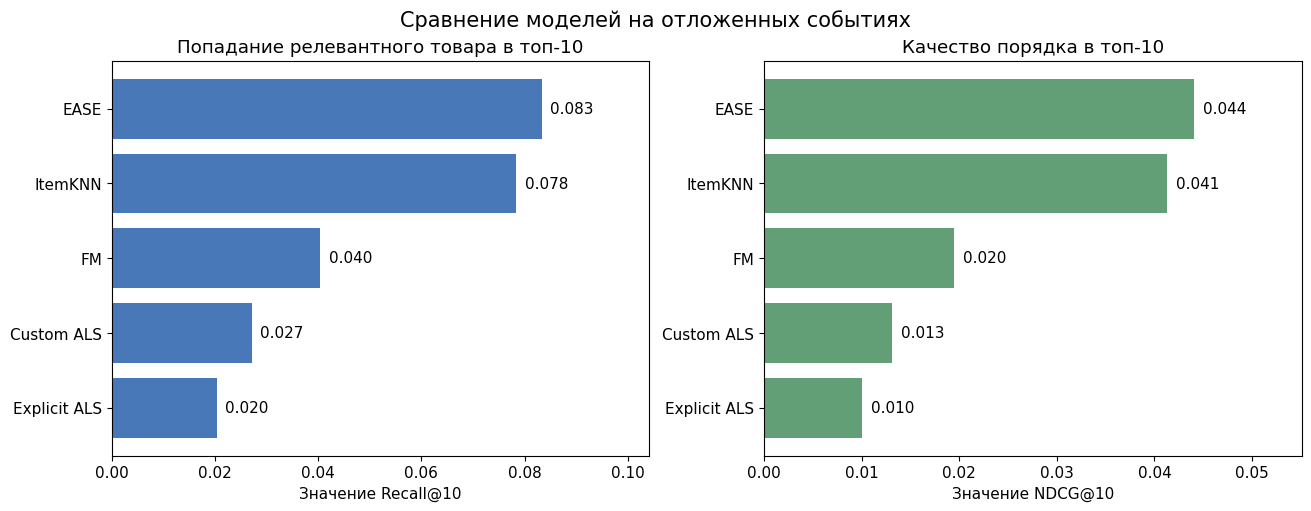

In [12]:
ordered = results.sort_values("Test Recall@10")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for axis, column, title, color in [
    (axes[0], "Test Recall@10", "Попадание релевантного товара в топ-10", "#4978b8"),
    (axes[1], "Test NDCG@10", "Качество порядка в топ-10", "#629f76"),
]:
    bars = axis.barh(ordered["Модель"], ordered[column], color=color)
    axis.set(title=title, xlabel=column.replace("Test ", "Значение "))
    axis.set_xlim(0, ordered[column].max() * 1.25)
    for bar, value in zip(bars, ordered[column]):
        axis.text(value + ordered[column].max() * 0.02, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
fig.suptitle("Сравнение моделей на отложенных событиях", fontsize=15)
plt.show()

## 6. Выводы

После подбора на validation лучший результат на test даёт EASE с регуляризацией $\lambda=100$: Recall@10 = **0,0833**, NDCG@10 = **0,0441**. Второй ItemKNN с Recall@10 = **0,0783**. 


У Custom ALS Recall@10 = 0,0271 vs 0,0203 у Explicit ALS. В целом дифф говорит о том что выбранный нами сигнал релевантен

FM достигла Recall@10 = 0,0404, но её покрытие каталога составило лишь 11,57%. Следовательно, модель чаще рекомендует сравнительно узкий набор объектов. У EASE одновременно выше Recall@10 и шире покрытие — 60,61%.